# Notebook 04: Topic Modelling Using Latent Dirichlet Allocation (LDA)

## Objectives

1. Load the final biomedical literature dataset.
2. Prepare a document-term matrix for topic modelling.
3. Apply Latent Dirichlet Allocation (LDA).
4. Identify the most representative terms for each topic.
5. Assign dominant topics to individual documents.
6. Compare topic distributions across the three analytical layers.
7. Visualise and export the results for thesis reporting.

## Dataset

The corpus consists of 21,256 PubMed records classified into three
author-defined analytical layers:

- L1: Scientific Engagement
- L2: Safety and Risk
- L3: Comparative and Critical

## Method

LDA is an unsupervised probabilistic topic-modelling technique.
It represents each document as a mixture of topics and each topic
as a probability distribution over words.

Topics will be interpreted by examining their high-probability
terms and representative documents.

The analytical layers are author-defined categories. The dataset
contains PubMed publications and abstracts, not direct transcripts
of Medical Science Liaison interactions.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

from pathlib import Path
from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# 2. LOAD DATASET
# ============================================================

DATASET_PATH = Path(
    "pubmed_medical_affairs_3layer_corpus_FINAL.csv"
)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH.resolve()}\n"
        "Check the notebook's working directory."
    )

df = pd.read_csv(DATASET_PATH)

required_columns = [
    "pmid",
    "title",
    "abstract",
    "year",
    "journal",
    "layer"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Preserve the original dataset and prepare a working copy
analysis_df = df.copy()

analysis_df["abstract"] = (
    analysis_df["abstract"]
    .fillna("")
    .astype(str)
    .str.strip()
)

analysis_df = analysis_df[
    (analysis_df["abstract"] != "")
    & analysis_df["layer"].notna()
].copy()

analysis_df = analysis_df.reset_index(drop=True)

print("Dataset loaded successfully.")
print("Records available:", len(analysis_df))

print("\nRecords per analytical layer:")
print(analysis_df["layer"].value_counts())

display(
    analysis_df[
        ["pmid", "title", "abstract", "layer"]
    ].head(3)
)

Dataset loaded successfully.
Records available: 21256

Records per analytical layer:
layer
L1_scientific_engagement    9599
L3_comparative_critical     5849
L2_safety_risk              5808
Name: count, dtype: int64


,pmid,title,abstract,layer
0,41483736,Intracranial activity of antibody-drug conjuga...,Antibody-drug conjugates (ADCs) represent a ra...,L1_scientific_engagement
1,41483728,Effect of quetiapine versus haloperidol on del...,INTRODUCTION: Delirium is a neuropsychiatric c...,L1_scientific_engagement
2,41483727,Vision-language models in diagnostic imaging: ...,BACKGROUND: Radiology faces an unprecedented w...,L1_scientific_engagement


In [3]:
# ============================================================
# 3. CREATE DOCUMENT-TERM MATRIX
# ============================================================

vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 1),
    min_df=10,
    max_df=0.90,
    max_features=15000,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
)

document_term_matrix = vectorizer.fit_transform(
    analysis_df["abstract"]
)

vocabulary = vectorizer.get_feature_names_out()

print("Document-term matrix created.")
print("Number of documents:", document_term_matrix.shape[0])
print("Vocabulary size:", document_term_matrix.shape[1])
print("Matrix type:", type(document_term_matrix).__name__)

print("\nExample vocabulary terms:")
print(vocabulary[:30])

Document-term matrix created.
Number of documents: 21256
Vocabulary size: 12436
Matrix type: csr_matrix

Example vocabulary terms:
['aa' 'aaa' 'aav' 'ab' 'abc' 'abdomen' 'abdominal' 'abdominis' 'abduction'
 'aberrant' 'aberrantly' 'aberrations' 'abi' 'abilities' 'ability'
 'abiotic' 'abiraterone' 'ablation' 'ablative' 'able' 'abnormal'
 'abnormalities' 'abnormality' 'abnormally' 'abortion' 'abroad'
 'abrocitinib' 'abscess' 'abscesses' 'absence']


In [4]:
# ============================================================
# 4. FIT LDA TOPIC MODEL
# ============================================================

N_TOPICS = 6

lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS,
    max_iter=10,
    learning_method="batch",
    random_state=42,
    n_jobs=-1
)

document_topic_matrix = lda_model.fit_transform(
    document_term_matrix
)

print("LDA model fitted successfully.")
print("Number of topics:", N_TOPICS)
print("Number of documents:", document_topic_matrix.shape[0])
print("Topic matrix shape:", document_topic_matrix.shape)
print("Model perplexity:", round(
    lda_model.perplexity(document_term_matrix), 2
))

LDA model fitted successfully.
Number of topics: 6
Number of documents: 21256
Topic matrix shape: (21256, 6)
Model perplexity: 2130.88


In [5]:
# ============================================================
# 5. EXTRACT TOP TERMS FOR EACH TOPIC
# ============================================================

def get_topic_terms(model, feature_names, top_n=15):

    topic_results = []

    for topic_index, topic_weights in enumerate(
        model.components_
    ):

        top_indices = topic_weights.argsort()[-top_n:][::-1]

        top_terms = feature_names[top_indices]

        top_weights = topic_weights[top_indices]

        for rank, (term, weight) in enumerate(
            zip(top_terms, top_weights),
            start=1
        ):

            topic_results.append({
                "topic": f"Topic {topic_index + 1}",
                "rank": rank,
                "term": term,
                "weight": float(weight)
            })

    return pd.DataFrame(topic_results)


topic_terms_df = get_topic_terms(
    lda_model,
    vocabulary,
    top_n=15
)

for topic_name, group in topic_terms_df.groupby("topic"):

    print("\n" + "=" * 60)
    print(topic_name)
    print("=" * 60)

    display(
        group[["rank", "term", "weight"]]
        .reset_index(drop=True)
    )

topic_terms_df.to_csv(
    "lda_topic_top_terms.csv",
    index=False
)

print("Saved: lda_topic_top_terms.csv")


Topic 1


,rank,term,weight
0,1,cancer,6244.908196
1,2,therapeutic,5988.421213
2,3,cell,5714.145773
3,4,immune,5582.879463
4,5,clinical,5325.410380
5,6,tumor,4758.471855
6,7,review,4649.235149
7,8,cells,3889.701458
8,9,potential,3583.270131
9,10,disease,3579.283893



Topic 2


,rank,term,weight
0,1,studies,5729.774502
1,2,data,4246.298321
2,3,care,3908.936533
3,4,review,3873.540398
4,5,health,3816.273381
5,6,clinical,3549.584217
6,7,ai,3536.822966
7,8,methods,2748.568425
8,9,research,2718.901470
9,10,patient,2683.644919



Topic 3


...


Topic 5


,rank,term,weight
0,1,patients,11499.088904
1,2,treatment,5844.660449
2,3,study,3430.279178
3,4,safety,3200.978584
4,5,group,3055.313979
5,6,adverse,2830.220014
6,7,mg,2808.382875
7,8,clinical,2636.876279
8,9,therapy,2580.340295
9,10,trial,2568.421347



Topic 6


,rank,term,weight
0,1,ci,9286.095713
1,2,studies,9071.182018
2,3,patients,7373.927561
3,4,outcomes,6676.895048
4,5,group,5952.203926
5,6,included,5876.065425
6,7,analysis,5500.797996
7,8,results,5129.397755
8,9,meta,5004.750491
9,10,risk,4761.108522


Saved: lda_topic_top_terms.csv


In [6]:
# ============================================================
# 6. ASSIGN DOMINANT TOPIC TO EACH DOCUMENT
# ============================================================

topic_columns = [
    f"topic_{i + 1}_probability"
    for i in range(N_TOPICS)
]

topic_probabilities_df = pd.DataFrame(
    document_topic_matrix,
    columns=topic_columns
)

analysis_df = pd.concat(
    [
        analysis_df.reset_index(drop=True),
        topic_probabilities_df
    ],
    axis=1
)

analysis_df["dominant_topic_number"] = (
    document_topic_matrix.argmax(axis=1) + 1
)

analysis_df["dominant_topic"] = (
    "Topic " +
    analysis_df["dominant_topic_number"].astype(str)
)

analysis_df["dominant_topic_probability"] = (
    document_topic_matrix.max(axis=1)
)

print("Dominant topics assigned.")

print("\nDominant topic distribution:")
print(
    analysis_df["dominant_topic"]
    .value_counts()
    .sort_index()
)

display(
    analysis_df[
        [
            "pmid",
            "title",
            "layer",
            "dominant_topic",
            "dominant_topic_probability"
        ]
    ].head(10)
)

analysis_df.to_csv(
    "lda_document_topic_assignments.csv",
    index=False
)

print("Saved: lda_document_topic_assignments.csv")

Dominant topics assigned.

Dominant topic distribution:
dominant_topic
Topic 1    4367
Topic 2    2936
Topic 3    3416
Topic 4    3579
Topic 5    2468
Topic 6    4490
Name: count, dtype: int64


,pmid,title,layer,dominant_topic,dominant_topic_probability
0,41483736,Intracranial activity of antibody-drug conjuga...,L1_scientific_engagement,Topic 1,0.783809
1,41483728,Effect of quetiapine versus haloperidol on del...,L1_scientific_engagement,Topic 6,0.956451
2,41483727,Vision-language models in diagnostic imaging: ...,L1_scientific_engagement,Topic 2,0.925562
3,41483666,The complexity of dystrophin transcription and...,L1_scientific_engagement,Topic 1,0.542066
4,41483580,EEG biomarkers for a precision-medicine approa...,L1_scientific_engagement,Topic 4,0.994493
5,41483505,The role of phototherapy in pediatric dermatol...,L1_scientific_engagement,Topic 4,0.638991
6,41483501,Tirzepatide in dermatology: cutaneous adverse ...,L1_scientific_engagement,Topic 4,0.643332
7,41483491,Homologous recombination deficiency in endomet...,L1_scientific_engagement,Topic 1,0.787305
8,41482263,Role of oral tetracyclines in preventing acnei...,L1_scientific_engagement,Topic 5,0.748431
9,41482234,"Integrating Nuclear Techniques, Isotopic Traci...",L1_scientific_engagement,Topic 3,0.351943


Saved: lda_document_topic_assignments.csv


In [7]:
# ============================================================
# 7. COMPARE TOPIC DISTRIBUTIONS ACROSS LAYERS
# ============================================================

topic_layer_counts = pd.crosstab(
    analysis_df["layer"],
    analysis_df["dominant_topic"]
)

print("Document counts by layer and dominant topic:")
display(topic_layer_counts)

# Row percentages make differently sized layers easier to compare
topic_layer_percentages = (
    pd.crosstab(
        analysis_df["layer"],
        analysis_df["dominant_topic"],
        normalize="index"
    ) * 100
)

print("\nPercentage distribution within each layer:")
display(topic_layer_percentages.round(2))

topic_layer_counts.to_csv(
    "lda_topic_counts_by_layer.csv"
)

topic_layer_percentages.to_csv(
    "lda_topic_percentages_by_layer.csv"
)

print("\nSaved topic distribution tables.")

Document counts by layer and dominant topic:


dominant_topic,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6
layer,,,,,,
L1_scientific_engagement,2668,684,1132,1415,1323,2377
L2_safety_risk,763,792,1121,982,926,1224
L3_comparative_critical,936,1460,1163,1182,219,889



Percentage distribution within each layer:


dominant_topic,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6
layer,,,,,,
L1_scientific_engagement,27.79,7.13,11.79,14.74,13.78,24.76
L2_safety_risk,13.14,13.64,19.30,16.91,15.94,21.07
L3_comparative_critical,16.00,24.96,19.88,20.21,3.74,15.20



Saved topic distribution tables.


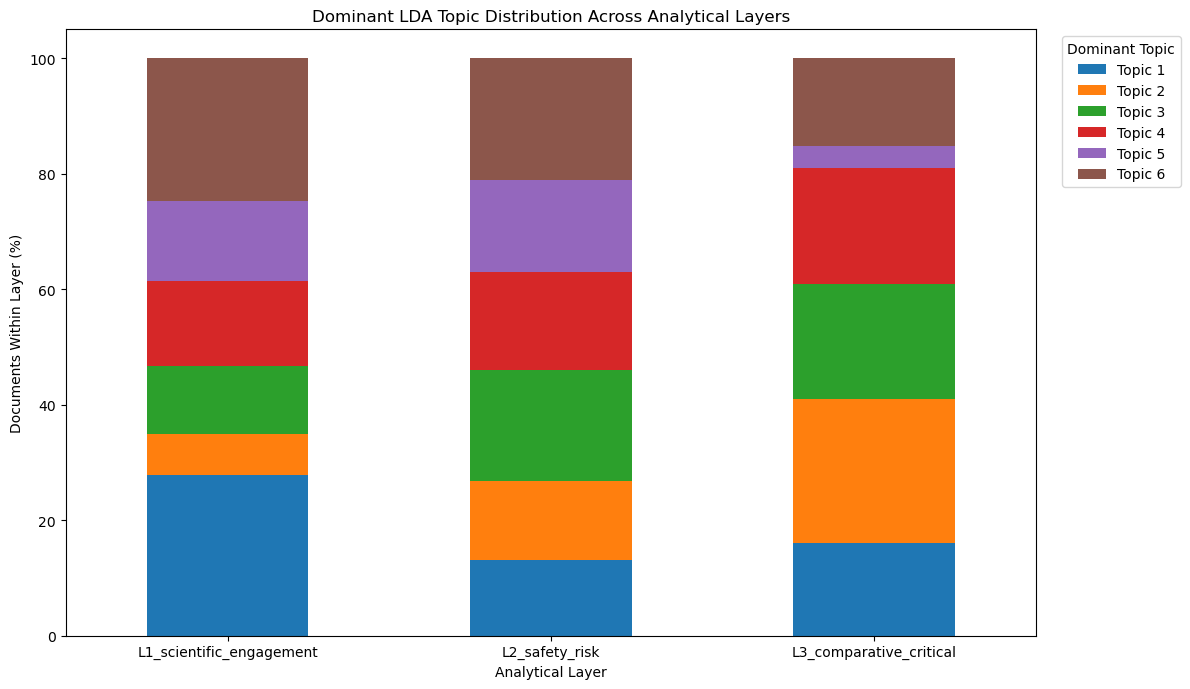

Saved: lda_topic_distribution_by_layer.png


In [8]:
# ============================================================
# 8. VISUALISE TOPIC DISTRIBUTIONS BY LAYER
# ============================================================

ax = topic_layer_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

ax.set_title(
    "Dominant LDA Topic Distribution Across Analytical Layers"
)

ax.set_xlabel("Analytical Layer")
ax.set_ylabel("Documents Within Layer (%)")

ax.legend(
    title="Dominant Topic",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "lda_topic_distribution_by_layer.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: lda_topic_distribution_by_layer.png")

In [9]:
# ============================================================
# 9. VALIDATE TOPICS USING REPRESENTATIVE ABSTRACTS
# ============================================================

for topic_number in range(1, N_TOPICS + 1):

    probability_column = f"topic_{topic_number}_probability"

    representative_docs = analysis_df.nlargest(
        5,
        probability_column
    )

    print("\n" + "=" * 80)
    print(f"TOPIC {topic_number}: REPRESENTATIVE DOCUMENTS")
    print("=" * 80)

    for _, row in representative_docs.iterrows():

        print("\nPMID:", row["pmid"])
        print("Title:", row["title"])
        print("Layer:", row["layer"])

        print(
            "Topic probability:",
            round(row[probability_column], 4)
        )

        print(
            "Abstract:",
            str(row["abstract"])[:700]
        )

        print("-" * 80)


TOPIC 1: REPRESENTATIVE DOCUMENTS

PMID: 41465422
Title: Glial Cells in the Early Stages of Neurodegeneration: Pathogenesis and Therapeutic Targets.
Layer: L3_comparative_critical
Topic probability: 0.9971
Abstract: Astrocytes and microglia constitute nearly half of all central nervous system cells and are indispensable for its proper function. Both exhibit striking morphological and functional heterogeneity, adopting either neuroprotective (A2, M2) or proinflammatory (A1, M1) phenotypes in response to cytokines, pathogen-associated molecular patterns (PAMPs)/damage-associated molecular patterns (DAMPs), toll-like receptor 4 (TLR4) activation, and NOD-like receptor family pyrin domain containing 3 (NLRP3) inflammasome signaling. Crucially, many of these phenotypic transitions arise during the earliest stages of neurodegeneration, when glial dysfunction precedes overt neuronal loss and may act as a prima
--------------------------------------------------------------------------------



In [10]:
# ============================================================
# 10. FINALISE PROVISIONAL TOPIC LABELS
# ============================================================

topic_labels = {
    1: "Cellular Mechanisms and Therapeutic Targets",
    2: "Healthcare Delivery, Implementation and Evaluation",
    3: "Drug Delivery Systems and Pharmaceutical Technologies",
    4: "Clinical Treatment and Disease Management",
    5: "Clinical Trials: Efficacy and Safety",
    6: "Systematic Reviews and Evidence Synthesis"
}

analysis_df["dominant_topic_label"] = (
    analysis_df["dominant_topic_number"].map(topic_labels)
)

print("Topic labels added.")

display(
    analysis_df[
        [
            "pmid",
            "title",
            "layer",
            "dominant_topic",
            "dominant_topic_label",
            "dominant_topic_probability"
        ]
    ].head(10)
)

analysis_df.to_csv(
    "lda_document_topic_assignments_labelled.csv",
    index=False
)

print("Saved: lda_document_topic_assignments_labelled.csv")

Topic labels added.


,pmid,title,layer,dominant_topic,dominant_topic_label,dominant_topic_probability
0,41483736,Intracranial activity of antibody-drug conjuga...,L1_scientific_engagement,Topic 1,Cellular Mechanisms and Therapeutic Targets,0.783809
1,41483728,Effect of quetiapine versus haloperidol on del...,L1_scientific_engagement,Topic 6,Systematic Reviews and Evidence Synthesis,0.956451
2,41483727,Vision-language models in diagnostic imaging: ...,L1_scientific_engagement,Topic 2,"Healthcare Delivery, Implementation and Evalua...",0.925562
3,41483666,The complexity of dystrophin transcription and...,L1_scientific_engagement,Topic 1,Cellular Mechanisms and Therapeutic Targets,0.542066
4,41483580,EEG biomarkers for a precision-medicine approa...,L1_scientific_engagement,Topic 4,Clinical Treatment and Disease Management,0.994493
5,41483505,The role of phototherapy in pediatric dermatol...,L1_scientific_engagement,Topic 4,Clinical Treatment and Disease Management,0.638991
6,41483501,Tirzepatide in dermatology: cutaneous adverse ...,L1_scientific_engagement,Topic 4,Clinical Treatment and Disease Management,0.643332
7,41483491,Homologous recombination deficiency in endomet...,L1_scientific_engagement,Topic 1,Cellular Mechanisms and Therapeutic Targets,0.787305
8,41482263,Role of oral tetracyclines in preventing acnei...,L1_scientific_engagement,Topic 5,Clinical Trials: Efficacy and Safety,0.748431
9,41482234,"Integrating Nuclear Techniques, Isotopic Traci...",L1_scientific_engagement,Topic 3,Drug Delivery Systems and Pharmaceutical Techn...,0.351943


Saved: lda_document_topic_assignments_labelled.csv
